# TP1 — Problème MNIST

**ETRS823** · Classification de chiffres manuscrits avec un réseau de neurones dense (Keras)

L'objectif de ce TP est d'étudier l'influence de trois choix de conception sur les performances d'un classifieur de chiffres manuscrits :

1. **la fonction d'activation** des couches ;
2. **l'algorithme d'optimisation** utilisé pour l'apprentissage ;
3. **la fonction de coût** minimisée.

Pour chaque configuration, on relève l'*accuracy* (proportion d'images correctement classées) sur les données d'entraînement et de test, ainsi que le nombre de synapses du réseau, c'est-à-dire son nombre de paramètres entraînables (poids + biais).

## Protocole expérimental

| Élément | Choix retenu |
|:--|:--|
| Données | MNIST : 60 000 images d'entraînement et 10 000 images de test, 28 × 28 pixels en niveaux de gris, 10 classes (chiffres 0 à 9) |
| Entrée du réseau | image aplatie en un vecteur de 784 valeurs, normalisées entre 0 et 1 |
| Apprentissage | 5 époques, lots de 32 images, soit 1 875 itérations par époque |
| Validation | sur le jeu de test (10 000 images), à la fin de chaque époque |
| Initialisation | graine aléatoire fixée à 42 avant chaque expérience |
| Mesures | accuracy d'entraînement et de test, nombre de synapses |

> Grâce à cette graine, une ré-exécution du notebook redonne les résultats présentés ici, à l'exception des variantes ReLU et tanh de la partie 1 : leur loss devient `nan` (instabilité numérique) et leur évolution peut alors varier d'une machine à l'autre.

## Préparation

### Bibliothèques et style des figures

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"      # masque les messages d'information de TensorFlow

import warnings
warnings.filterwarnings("ignore", message=".*input_shape.*")   # avertissement Keras 3 sans conséquence

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Figures nettes (haute résolution) et style homogène pour tout le notebook
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.dpi": 100,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlepad": 10,
    "axes.labelsize": 11,
    "axes.edgecolor": "#444444",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.formatter.useoffset": False,
    "grid.color": "#dddddd",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
    "lines.linewidth": 2.2,
    "lines.markersize": 6.5,
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

### Chargement et mise en forme des données

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Entrées : chaque image 28 × 28 devient un vecteur de 784 valeurs comprises entre 0 et 1
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0

# Étiquettes : y_train / y_test restent des entiers de 0 à 9 ;
# version one-hot (vecteurs de 10 composantes) pour categorical_crossentropy et binary_crossentropy
y_train_cat = tf.keras.utils.to_categorical(y_train, 10)
y_test_cat = tf.keras.utils.to_categorical(y_test, 10)

print(f"x_train : {x_train.shape}   y_train : {y_train.shape}   y_train_cat : {y_train_cat.shape}")
print(f"x_test  : {x_test.shape}   y_test  : {y_test.shape}   y_test_cat  : {y_test_cat.shape}")

x_train : (60000, 784)   y_train : (60000,)   y_train_cat : (60000, 10)
x_test  : (10000, 784)   y_test  : (10000,)   y_test_cat  : (10000, 10)


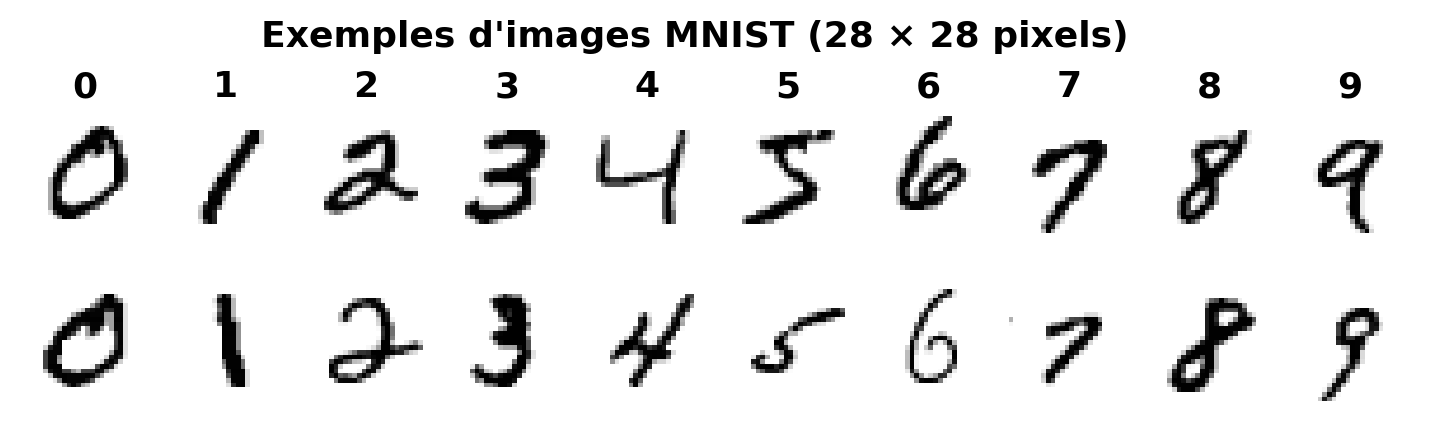

In [3]:
# Aperçu des données : les deux premiers exemples de chaque chiffre du jeu d'entraînement
fig, axes = plt.subplots(2, 10, figsize=(9, 2.1), gridspec_kw={"hspace": 0.08, "wspace": 0.08})
for chiffre in range(10):
    for ligne, i in enumerate(np.flatnonzero(y_train == chiffre)[:2]):
        axes[ligne, chiffre].imshow(x_train[i].reshape(28, 28), cmap="gray_r")
        axes[ligne, chiffre].axis("off")
    axes[0, chiffre].set_title(str(chiffre), fontsize=13, pad=4)
fig.suptitle("Exemples d'images MNIST (28 × 28 pixels)", fontsize=13, fontweight="bold", y=1.06)
plt.show()

### Fonctions utilitaires

Toutes les expériences suivent le même déroulé, regroupé dans la fonction `entrainer` : apprentissage sur 5 époques, évaluation sur le jeu de test, bilan des neurones et des synapses, puis tracé des courbes d'apprentissage. La fonction `comparer` produit la figure de synthèse de chaque partie.

In [4]:
EPOCHS = 5
BATCH_SIZE = 32                      # 60 000 / 32 = 1 875 itérations par époque

COULEUR_TRAIN = "#E15759"            # courbes d'entraînement
COULEUR_VAL = "#4E79A7"              # courbes de validation
PALETTE = ["#4E79A7", "#F28E2B", "#59A14F", "#B07AA1"]
STYLES = [("o", "-"), ("s", "--"), ("D", "-."), ("^", ":")]      # (marqueur, trait) par variante


def classifieur_softmax_simple():
    """Classifieur à une couche : 784 entrées -> 10 neurones softmax (7 850 synapses)."""
    return tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='softmax', input_shape=(784,))
    ])


def resume_synapses(model):
    """Affiche le nombre de neurones et de synapses (poids + biais) de chaque couche dense."""
    print("\n--- Model Summary (Neurons and Synapses) ---")
    total_neurones = 0
    for couche in model.layers:
        if isinstance(couche, tf.keras.layers.Dense):
            poids, biais = couche.get_weights()
            total_neurones += couche.units
            print(f"Layer: {couche.name} (Dense), Parameters: {couche.count_params()}, "
                  f"Neurons: {couche.units}, Weights: {poids.size}, Bias: {biais.size}, "
                  f"Calculated Synapses (Weights + Bias): {poids.size + biais.size}")
    total_synapses = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f"\nTotal Neurons (approx, mainly from Dense/RNN): {total_neurones}")
    print(f"Total Synapses (Total Trainable Parameters): {total_synapses}")


def annoter_valeurs_finales(ax, x, points, ecart_min=14):
    """Écrit la dernière valeur de chaque courbe à droite du point, sans chevauchement."""
    (v_bas, c_bas), (v_haut, c_haut) = sorted(points)
    y_min, y_max = ax.get_ylim()
    hauteur = ax.get_window_extent().height * 72 / ax.figure.dpi      # hauteur des axes en points
    ecart = (v_haut - v_bas) / (y_max - y_min) * hauteur
    decalage = max(0.0, (ecart_min - ecart) / 2)
    for valeur, couleur, dy in ((v_bas, c_bas, -decalage), (v_haut, c_haut, decalage)):
        ax.annotate(f"{valeur:.4f}", xy=(x, valeur), xytext=(9, dy), textcoords="offset points",
                    va="center", color=couleur, fontsize=10, fontweight="bold")


def tracer_historique(h, titre, test_loss=None):
    """Courbes d'accuracy par époque : entraînement et validation."""
    epoques = np.arange(1, len(h["accuracy"]) + 1)
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    ax.plot(epoques, h["accuracy"], "o-", color=COULEUR_TRAIN, label="Entraînement")
    ax.plot(epoques, h["val_accuracy"], "o-", color=COULEUR_VAL, label="Validation")
    ax.set_xticks(epoques)
    ax.set_xlim(0.75, epoques[-1] + 0.65)
    ax.margins(y=0.12)
    annoter_valeurs_finales(ax, epoques[-1], [(h["accuracy"][-1], COULEUR_TRAIN),
                                              (h["val_accuracy"][-1], COULEUR_VAL)])
    ax.set_title(titre, loc="left")
    if test_loss is not None:                  # loss finale sur le jeu de test (en rouge si nan)
        diverge = bool(np.isnan(test_loss))
        ax.set_title(f"loss (test) : {test_loss:.4f}", loc="right", fontsize=10,
                     fontweight="bold" if diverge else "normal",
                     color="#C0392B" if diverge else "#707070")
    ax.set_xlabel("Époque")
    ax.set_ylabel("Accuracy")
    ax.legend(loc="best")
    plt.show()


def entrainer(model, titre, y_tr=None, y_te=None):
    """Entraîne le modèle, l'évalue sur le jeu de test, affiche le bilan et la courbe d'apprentissage."""
    y_tr = y_train_cat if y_tr is None else y_tr
    y_te = y_test_cat if y_te is None else y_te
    historique = model.fit(x_train, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE,
                           validation_data=(x_test, y_te))
    test_loss, test_acc = model.evaluate(x_test, y_te)
    print(f"Test accuracy: {test_acc:.4f}")
    resume_synapses(model)
    tracer_historique(historique.history, titre, test_loss)
    return {"history": historique.history, "test_acc": test_acc, "test_loss": test_loss}


def comparer(resultats, titre, hasard=False):
    """Compare les variantes : accuracy de validation par époque et accuracy finale sur le test."""
    noms = list(resultats)
    couleurs = PALETTE[:len(noms)]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1.35, 1]})

    # À gauche : évolution de l'accuracy de validation
    for nom, couleur, (marqueur, trait) in zip(noms, couleurs, STYLES):
        val = resultats[nom]["history"]["val_accuracy"]
        epoques = np.arange(1, len(val) + 1)
        ax1.plot(epoques, val, marker=marqueur, linestyle=trait, color=couleur, label=nom)
    ax1.set_xticks(epoques)
    ax1.set_title("Accuracy de validation par époque", loc="left")
    ax1.set_xlabel("Époque")
    ax1.set_ylabel("Accuracy")

    # À droite : accuracy finale sur le jeu de test (un point par variante)
    acc = np.array([resultats[nom]["test_acc"] for nom in noms])
    rang = np.arange(len(noms))[::-1]
    etendue = max(acc.max() - acc.min(), 0.01)
    ax2.set_xlim(max(0.0, acc.min() - 0.25 * etendue), min(1.0, acc.max() + 0.15 * etendue))
    ax2.scatter(acc, rang, color=couleurs, s=110, zorder=3, edgecolor="white", linewidth=1.5)
    for r, a in zip(rang, acc):
        ax2.annotate(f"{a:.4f}", xy=(a, r), xytext=(0, 11), textcoords="offset points",
                     ha="center", fontsize=10, fontweight="bold")
    ax2.set_yticks(rang, noms)
    ax2.set_ylim(-0.6, len(noms) - 0.3)
    ax2.set_title("Accuracy finale sur le jeu de test", loc="left")
    ax2.set_xlabel("Accuracy")
    ax2.locator_params(axis="x", nbins=4)      # graduations aérées

    if hasard:                                 # niveau du hasard : 1 chance sur 10
        ax1.set_ylim(0, 1)
        ax1.axhline(0.1, color="#999999", linestyle="--", linewidth=1, zorder=0)
        ax1.annotate("niveau du hasard (0.10)", xy=(1, 0.1), xytext=(0, -6),
                     textcoords="offset points", va="top", fontsize=9, color="#777777")
        ax2.axvline(0.1, color="#999999", linestyle="--", linewidth=1, zorder=0)
        ax1.legend(loc="center right")
    else:
        ax1.legend(loc="best")

    fig.suptitle(titre, x=0.01, ha="left", fontsize=14, fontweight="bold")
    fig.tight_layout()
    plt.show()


# Résultats de chaque partie, remplis au fil des expériences
res_activation, res_optimiseur, res_cout = {}, {}, {}

---

## 1. Choix de la fonction d'activation

Seule la fonction d'activation change d'une variante à l'autre ; elle est appliquée à toutes les couches, y compris la couche de sortie. Les quatre modèles sont compilés de la même façon : optimiseur Adam et entropie croisée catégorielle (`categorical_crossentropy`).

### a) Softmax

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8834 - loss: 0.4080 - val_accuracy: 0.8825 - val_loss: 0.4078
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8825 - loss: 0.4078
Test accuracy: 0.8825

--- Model Summary (Neurons and Synapses) ---
Layer: dense_22 (Dense), Parameters: 401920, Neurons: 512, Weights: 401408, Bias: 512, Calculated Synapses (Weights + Bias): 401920
Layer: dense_23 (Dense), Parameters: 5130, Neurons: 10, Weights: 5120, Bias: 10, Calculated Synapses (Weights + Bias): 5130

Total Neurons (approx, mainly from Dense/RNN): 522
Total Synapses (Total Trainable Parameters): 407050


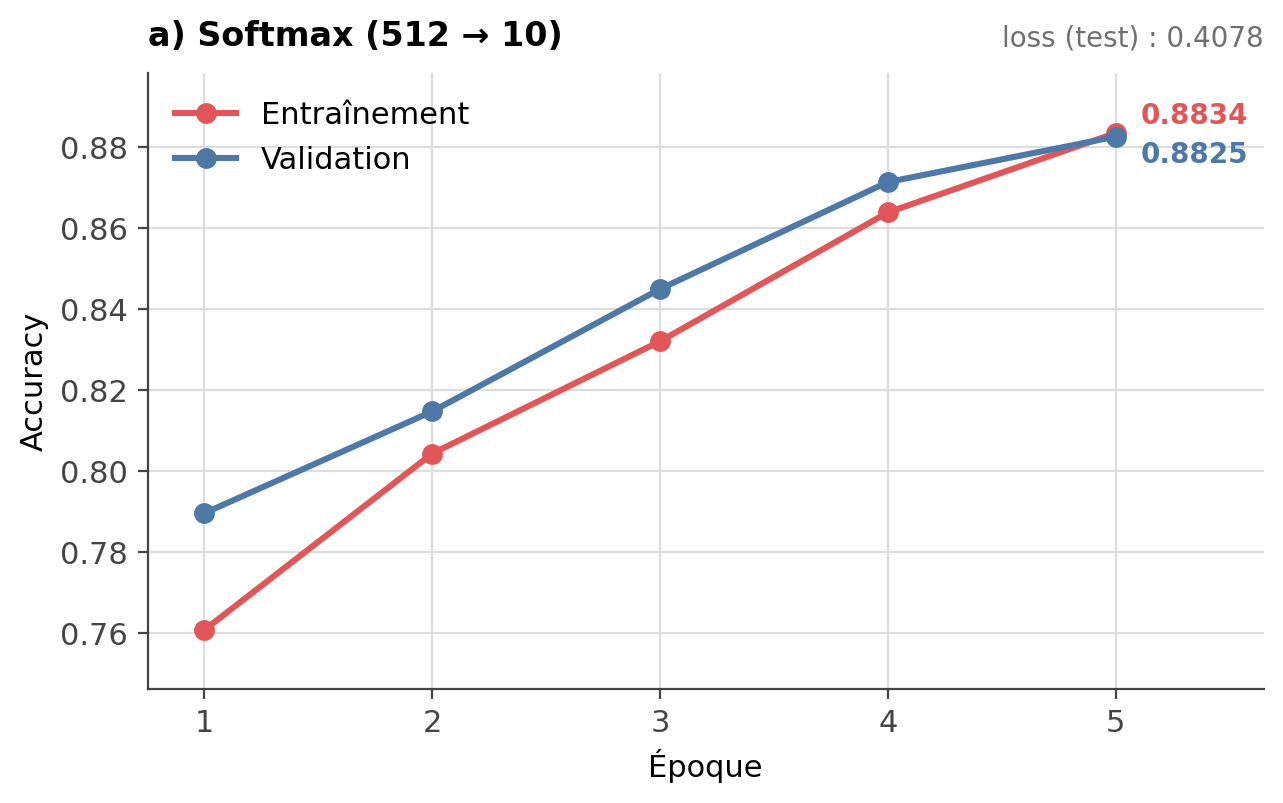

In [5]:
# Softmax : couche cachée de 512 neurones + sortie de 10 neurones
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation='softmax', input_shape=(784,)),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_activation["Softmax"] = entrainer(model, "a) Softmax (512 → 10)")

### b) ReLU

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7574 - loss: nan - val_accuracy: 0.7679 - val_loss: nan
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7679 - loss: nan
Test accuracy: 0.7679

--- Model Summary (Neurons and Synapses) ---
Layer: dense_27 (Dense), Parameters: 401920, Neurons: 512, Weights: 401408, Bias: 512, Calculated Synapses (Weights + Bias): 401920
Layer: dense_28 (Dense), Parameters: 131328, Neurons: 256, Weights: 131072, Bias: 256, Calculated Synapses (Weights + Bias): 131328
Layer: dense_29 (Dense), Parameters: 2570, Neurons: 10, Weights: 2560, Bias: 10, Calculated Synapses (Weights + Bias): 2570

Total Neurons (approx, mainly from Dense/RNN): 778
Total Synapses (Total Trainable Parameters): 535818


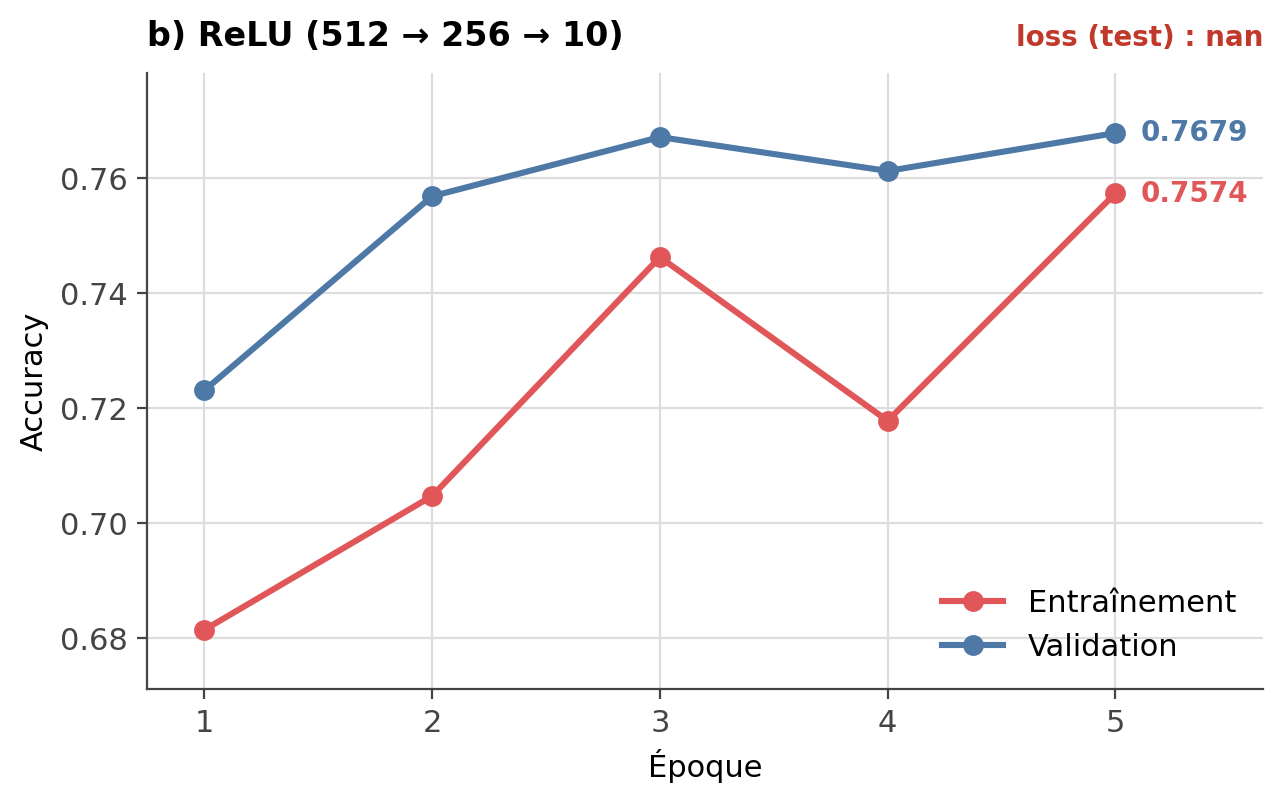

In [6]:
# ReLU : deux couches cachées (512 et 256 neurones) + sortie de 10 neurones
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation='relu', input_shape=(784,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(10, activation='relu')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_activation["ReLU"] = entrainer(model, "b) ReLU (512 → 256 → 10)")

### c) tanh

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.0992 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1009 - loss: nan
Test accuracy: 0.1009

--- Model Summary (Neurons and Synapses) ---
Layer: dense_30 (Dense), Parameters: 401920, Neurons: 512, Weights: 401408, Bias: 512, Calculated Synapses (Weights + Bias): 401920
Layer: dense_31 (Dense), Parameters: 5130, Neurons: 10, Weights: 5120, Bias: 10, Calculated Synapses (Weights + Bias): 5130

Total Neurons (approx, mainly from Dense/RNN): 522
Total Synapses (Total Trainable Parameters): 407050


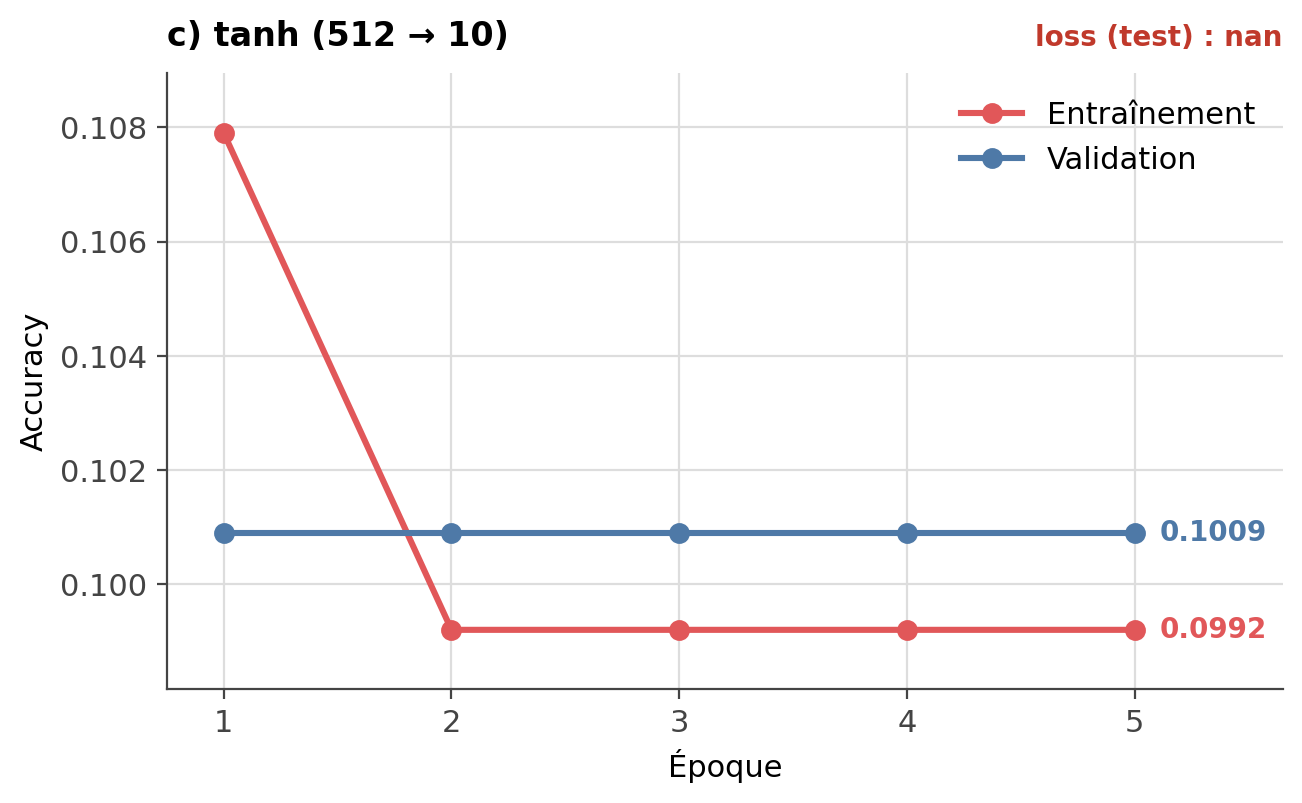

In [7]:
# tanh : couche cachée de 512 neurones + sortie de 10 neurones
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation='tanh', input_shape=(784,)),
    tf.keras.layers.Dense(10, activation='tanh')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_activation["tanh"] = entrainer(model, "c) tanh (512 → 10)")

### d) Sigmoïde

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9835 - loss: 0.0560 - val_accuracy: 0.9768 - val_loss: 0.0759
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9768 - loss: 0.0759
Test accuracy: 0.9768

--- Model Summary (Neurons and Synapses) ---
Layer: dense_32 (Dense), Parameters: 401920, Neurons: 512, Weights: 401408, Bias: 512, Calculated Synapses (Weights + Bias): 401920
Layer: dense_33 (Dense), Parameters: 5130, Neurons: 10, Weights: 5120, Bias: 10, Calculated Synapses (Weights + Bias): 5130

Total Neurons (approx, mainly from Dense/RNN): 522
Total Synapses (Total Trainable Parameters): 407050


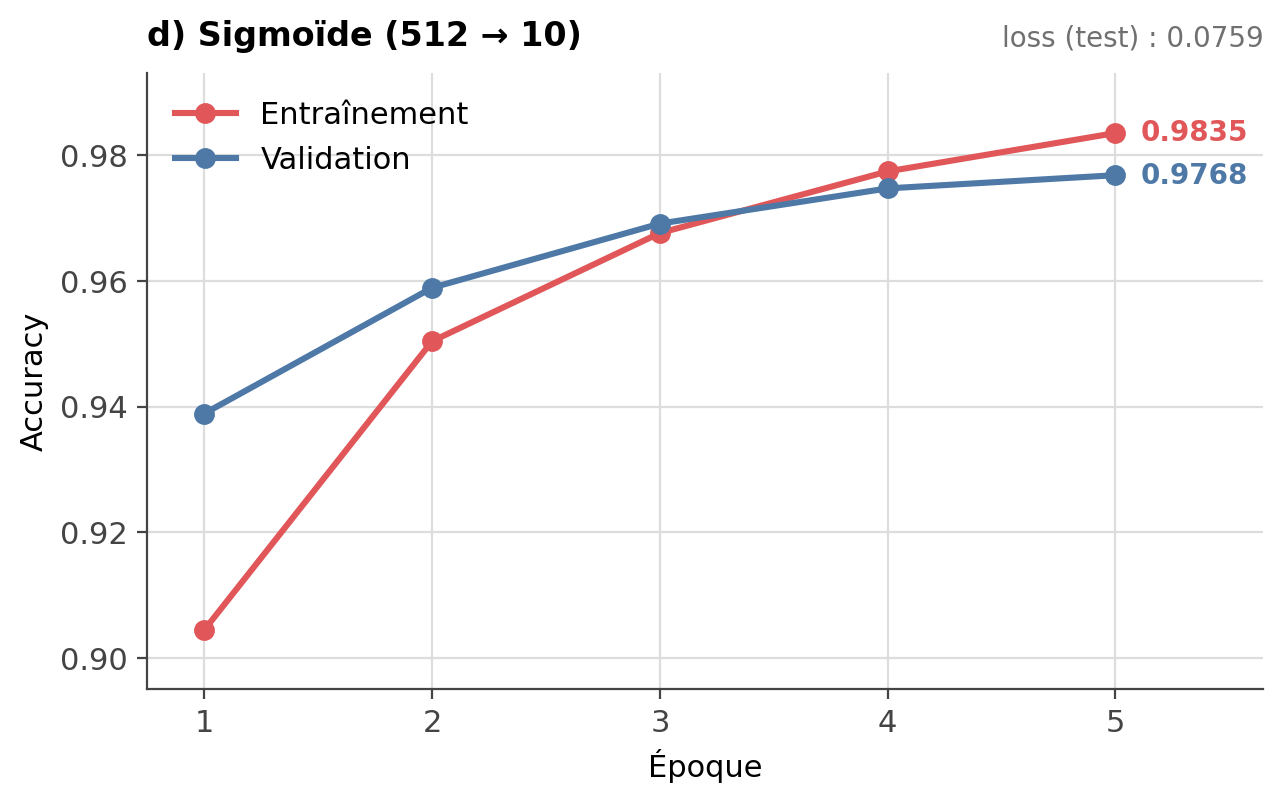

In [8]:
# Sigmoïde : couche cachée de 512 neurones + sortie de 10 neurones
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation='sigmoid', input_shape=(784,)),
    tf.keras.layers.Dense(10, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_activation["Sigmoïde"] = entrainer(model, "d) Sigmoïde (512 → 10)")

### Synthèse

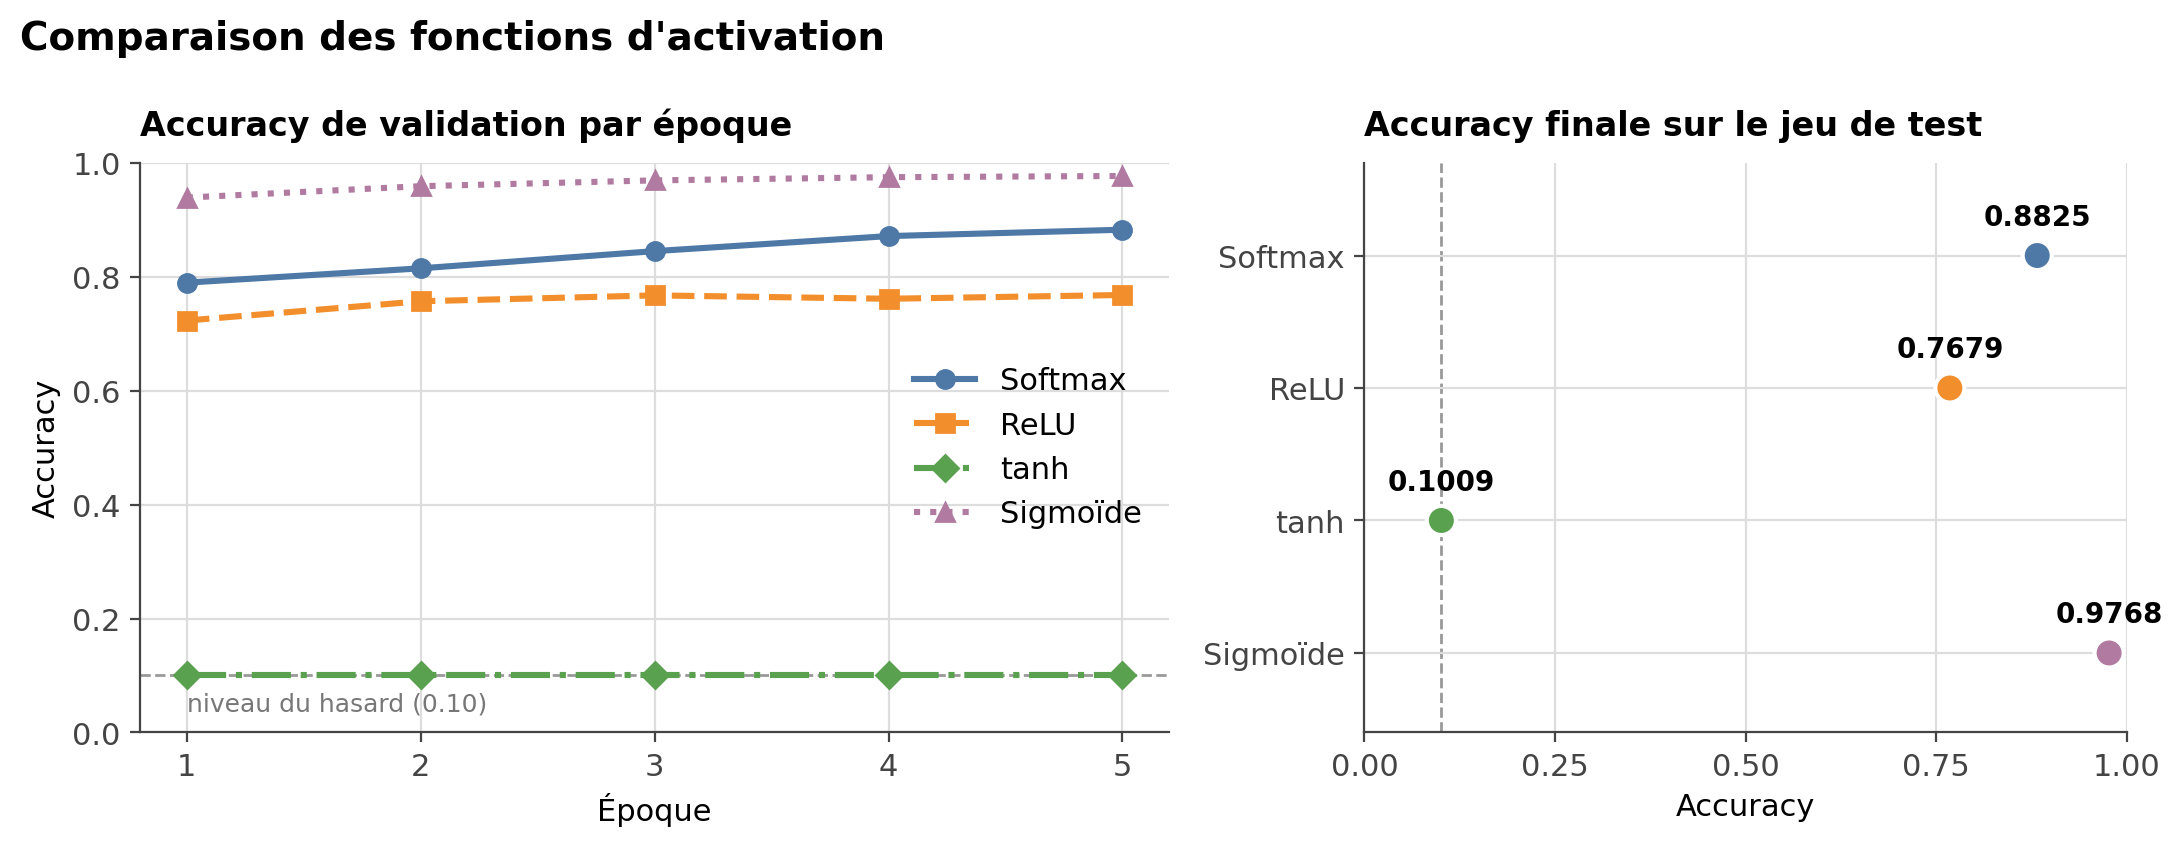

In [9]:
comparer(res_activation, "Comparaison des fonctions d'activation", hasard=True)

### Tableau récapitulatif

| Fonction d'activation | Accuracy entraînement | Accuracy test | Époques | Synapses | Conclusion |
|:--|--:|--:|:-:|--:|:--|
| Softmax | 0.8834 | 0.8825 | 5 | 407 050 | Best |
| ReLU | 0.7574 | 0.7679 | 5 | 535 818 | Mauvais rapport ressource/précision |
| tanh | 0.0992 | 0.1009 | 5 | 407 050 | Diverge |
| Sigmoïde | 0.9835 | 0.9768 | 5 | 407 050 | Un poil moins bien |

---

## 2. Choix de l'algorithme d'optimisation

Le réseau est réduit à une seule couche dense de 10 neurones avec activation softmax : 784 × 10 poids + 10 biais, soit 7 850 synapses. Seul l'optimiseur change ; la fonction de coût reste `categorical_crossentropy`.

### a) SGD

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9016 - loss: 0.3585 - val_accuracy: 0.9089 - val_loss: 0.3343
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9089 - loss: 0.3343
Test accuracy: 0.9089

--- Model Summary (Neurons and Synapses) ---
Layer: dense_2 (Dense), Parameters: 7850, Neurons: 10, Weights: 7840, Bias: 10, Calculated Synapses (Weights + Bias): 7850

Total Neurons (approx, mainly from Dense/RNN): 10
Total Synapses (Total Trainable Parameters): 7850


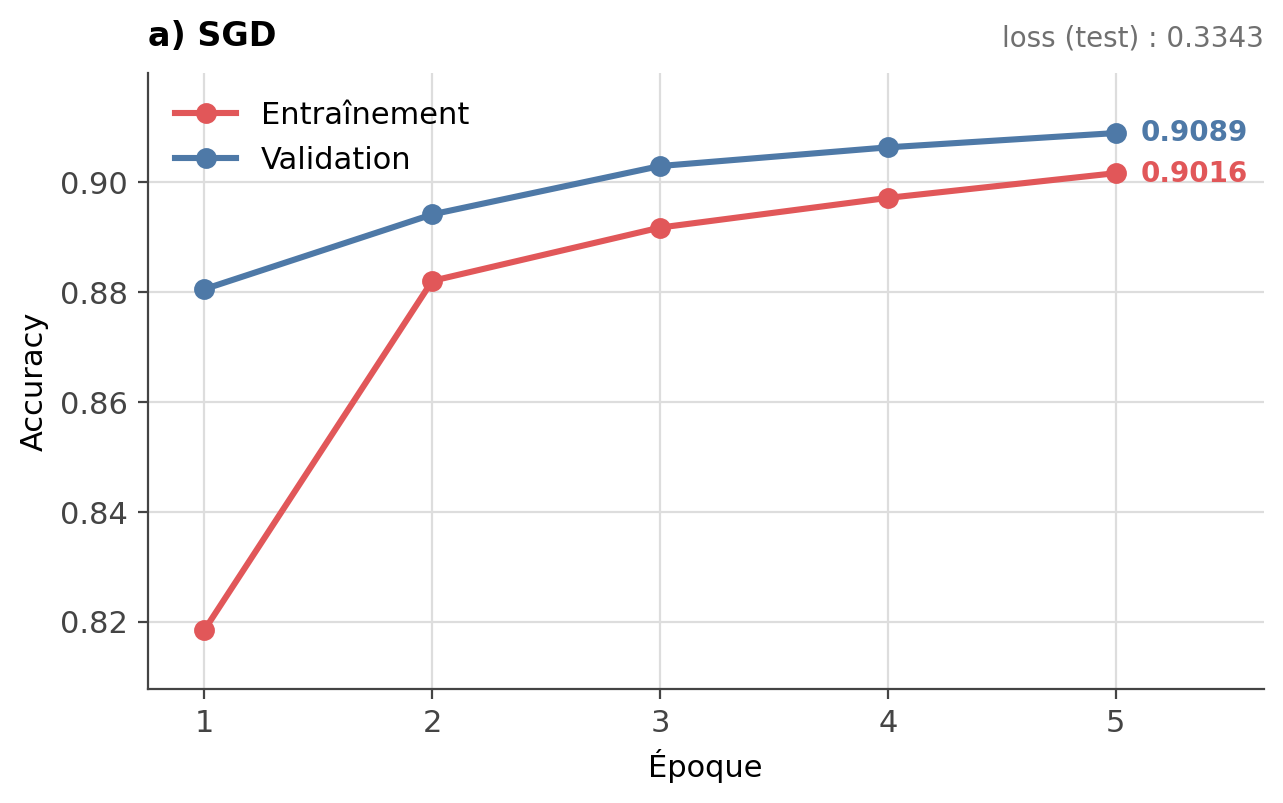

In [10]:
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = classifieur_softmax_simple()        # Dense(10, softmax) : 7 850 synapses

# Compile model
model.compile(optimizer='SGD',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_optimiseur["SGD"] = entrainer(model, "a) SGD")

### b) Adam

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9262 - loss: 0.2667 - val_accuracy: 0.9261 - val_loss: 0.2677
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9261 - loss: 0.2677
Test accuracy: 0.9261

--- Model Summary (Neurons and Synapses) ---
Layer: dense_1 (Dense), Parameters: 7850, Neurons: 10, Weights: 7840, Bias: 10, Calculated Synapses (Weights + Bias): 7850

Total Neurons (approx, mainly from Dense/RNN): 10
Total Synapses (Total Trainable Parameters): 7850


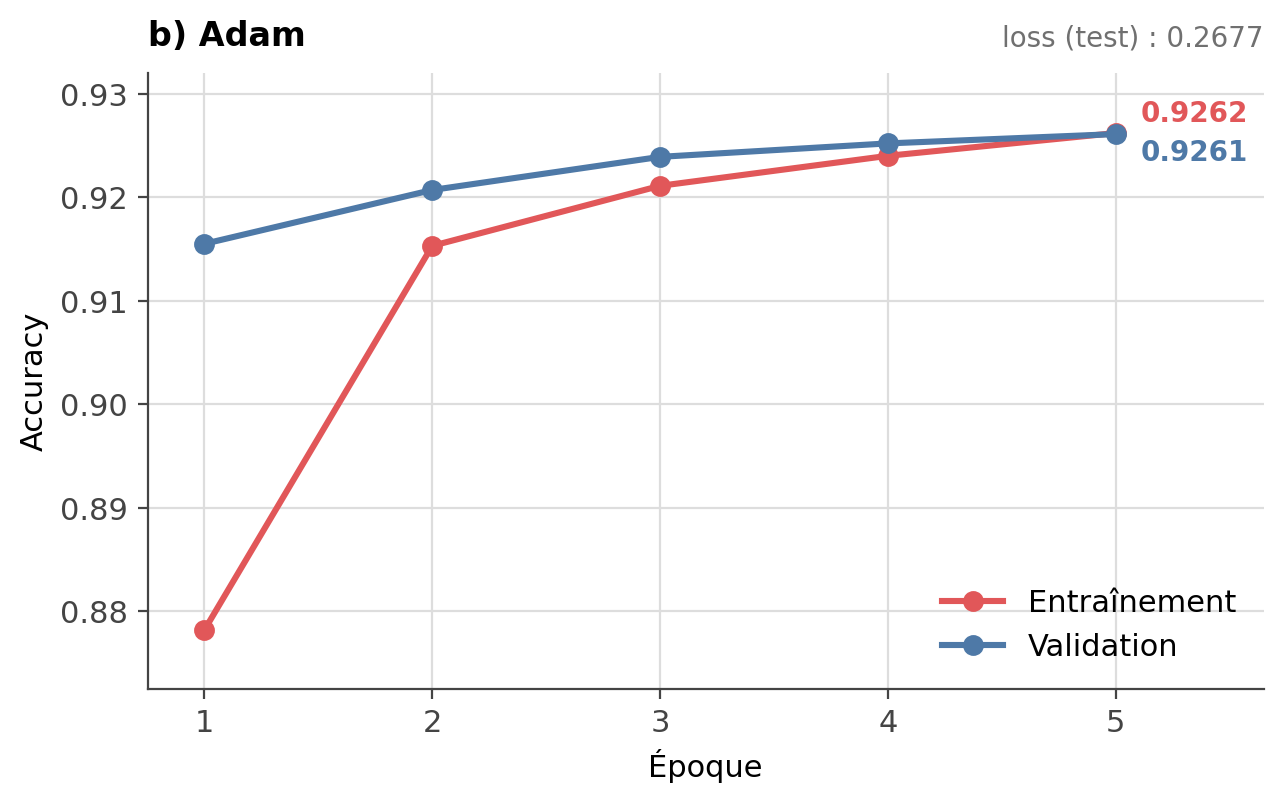

In [11]:
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = classifieur_softmax_simple()        # Dense(10, softmax) : 7 850 synapses

# Compile model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_optimiseur["Adam"] = entrainer(model, "b) Adam")

### c) RMSprop

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9248 - loss: 0.2802 - val_accuracy: 0.9247 - val_loss: 0.2797
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9247 - loss: 0.2797
Test accuracy: 0.9247

--- Model Summary (Neurons and Synapses) ---
Layer: dense_3 (Dense), Parameters: 7850, Neurons: 10, Weights: 7840, Bias: 10, Calculated Synapses (Weights + Bias): 7850

Total Neurons (approx, mainly from Dense/RNN): 10
Total Synapses (Total Trainable Parameters): 7850


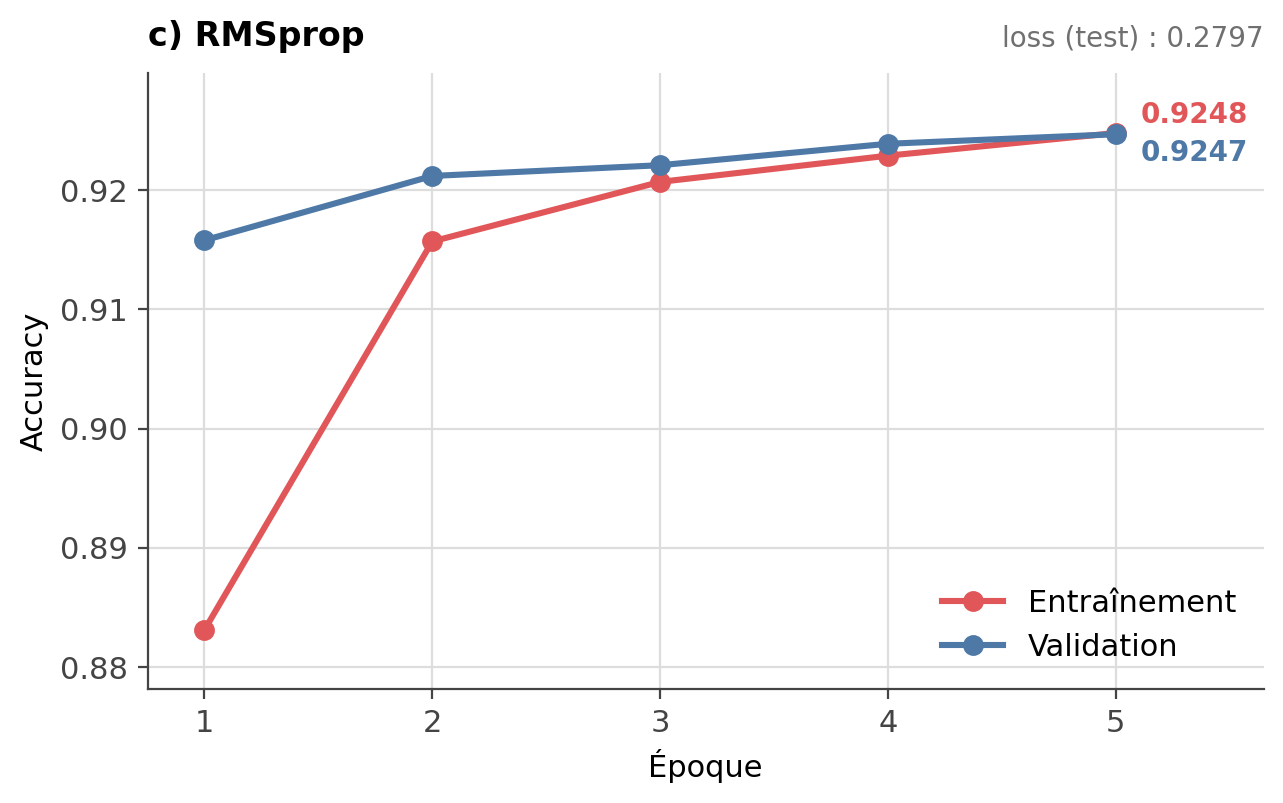

In [12]:
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = classifieur_softmax_simple()        # Dense(10, softmax) : 7 850 synapses

# Compile model
model.compile(optimizer='RMSprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_optimiseur["RMSprop"] = entrainer(model, "c) RMSprop")

### d) Adagrad

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8416 - loss: 0.7283 - val_accuracy: 0.8560 - val_loss: 0.6798
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8560 - loss: 0.6798
Test accuracy: 0.8560

--- Model Summary (Neurons and Synapses) ---
Layer: dense_4 (Dense), Parameters: 7850, Neurons: 10, Weights: 7840, Bias: 10, Calculated Synapses (Weights + Bias): 7850

Total Neurons (approx, mainly from Dense/RNN): 10
Total Synapses (Total Trainable Parameters): 7850


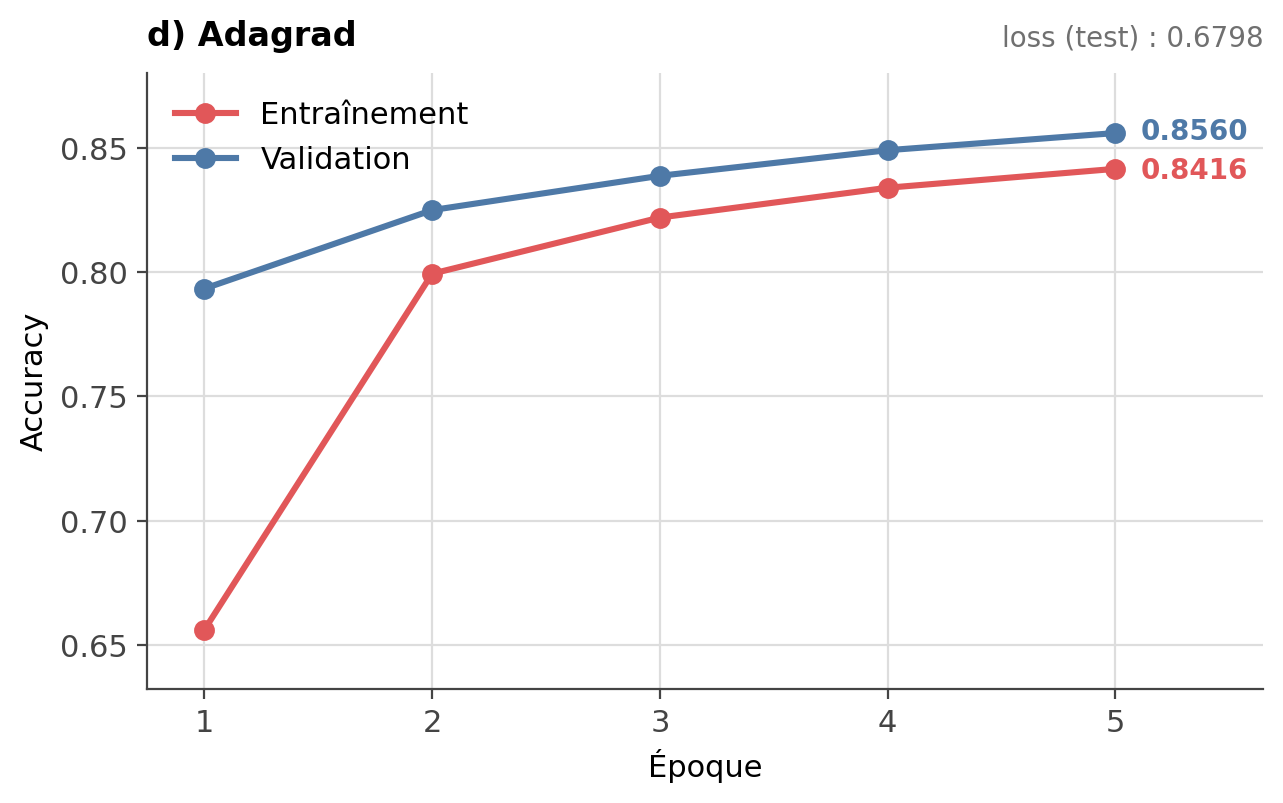

In [13]:
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = classifieur_softmax_simple()        # Dense(10, softmax) : 7 850 synapses

# Compile model
model.compile(optimizer='Adagrad',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_optimiseur["Adagrad"] = entrainer(model, "d) Adagrad")

### Synthèse

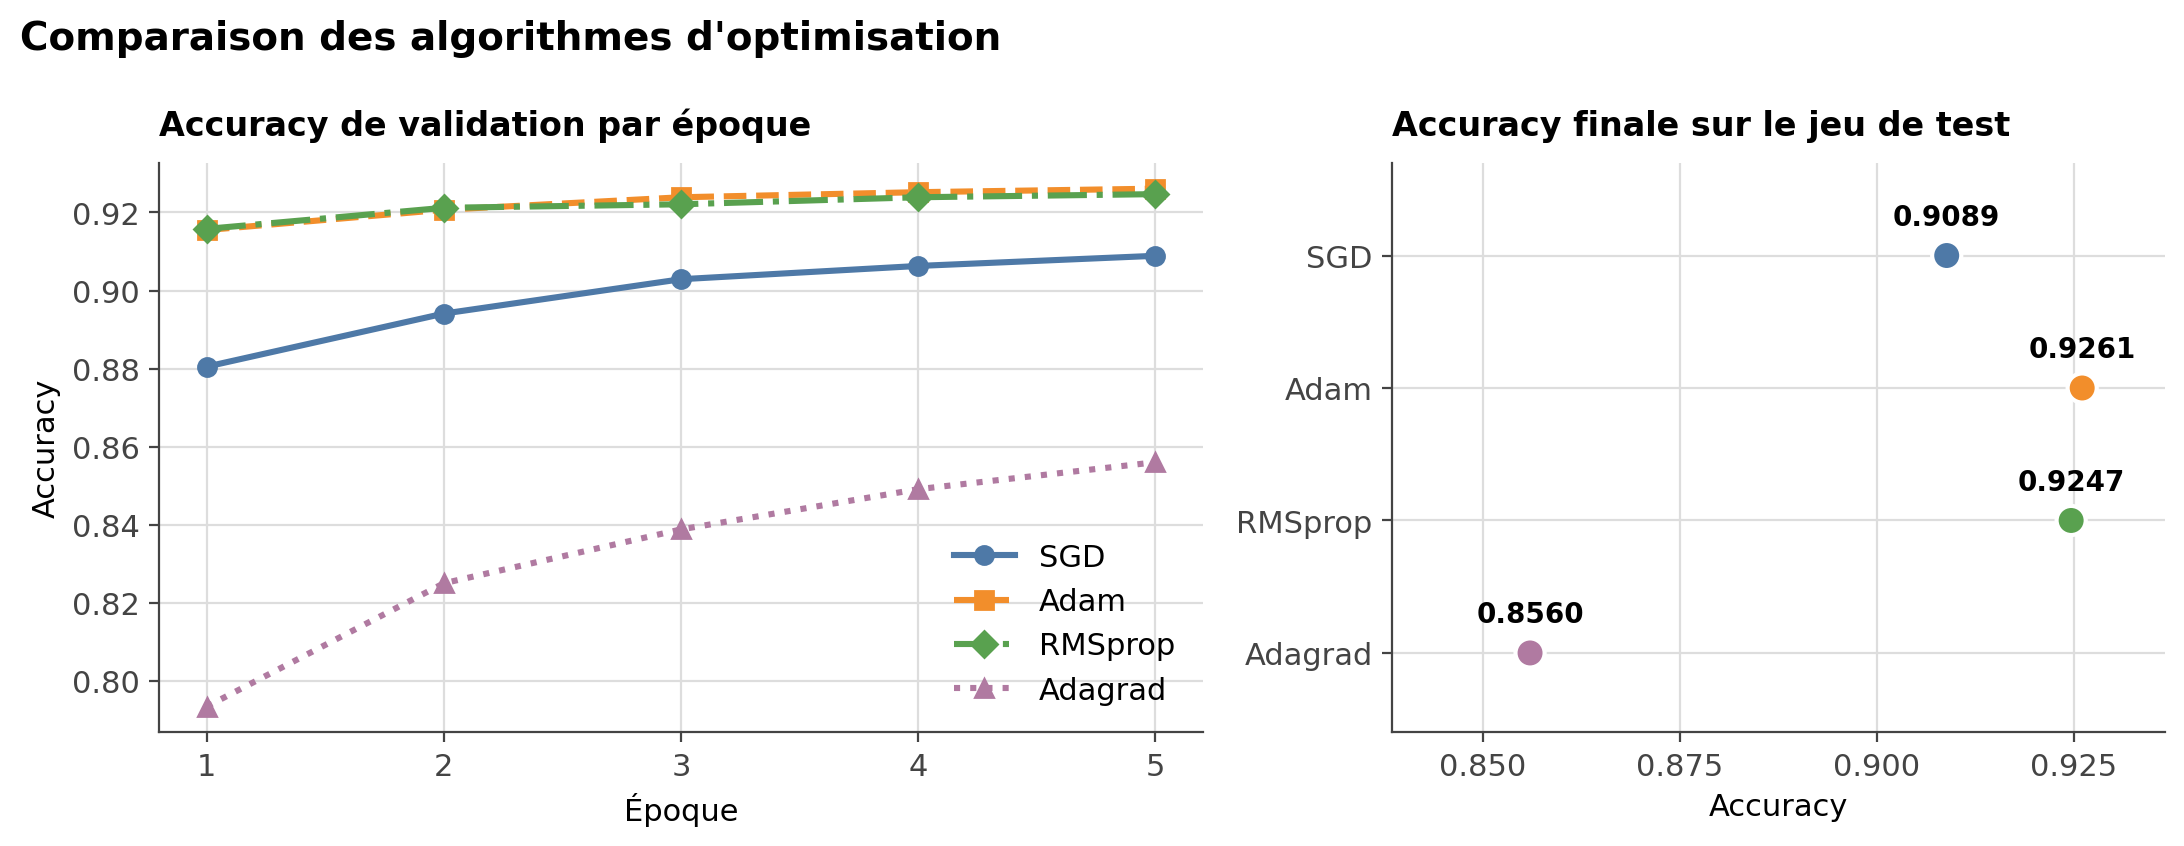

In [14]:
comparer(res_optimiseur, "Comparaison des algorithmes d'optimisation")

### Tableau récapitulatif

| Optimiseur | Accuracy entraînement | Accuracy test | Époques | Synapses | Conclusion |
|:--|--:|--:|:-:|--:|:--|
| SGD | 0.9016 | 0.9089 | 5 | 7 850 |  |
| Adam | 0.9262 | 0.9261 | 5 | 7 850 |  |
| RMSprop | 0.9248 | 0.9247 | 5 | 7 850 |  |
| Adagrad | 0.8416 | 0.8560 | 5 | 7 850 |  |

---

## 3. Choix de la fonction de coût

Même classifieur à une couche (7 850 synapses), entraîné avec Adam. `binary_crossentropy` et `categorical_crossentropy` utilisent les étiquettes encodées en one-hot (`y_train_cat`), tandis que `sparse_categorical_crossentropy` prend directement les étiquettes entières (`y_train`).

### a) `binary_crossentropy`

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9153 - loss: 0.0675 - val_accuracy: 0.9163 - val_loss: 0.0655
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9163 - loss: 0.0655
Test accuracy: 0.9163

--- Model Summary (Neurons and Synapses) ---
Layer: dense_15 (Dense), Parameters: 7850, Neurons: 10, Weights: 7840, Bias: 10, Calculated Synapses (Weights + Bias): 7850

Total Neurons (approx, mainly from Dense/RNN): 10
Total Synapses (Total Trainable Parameters): 7850


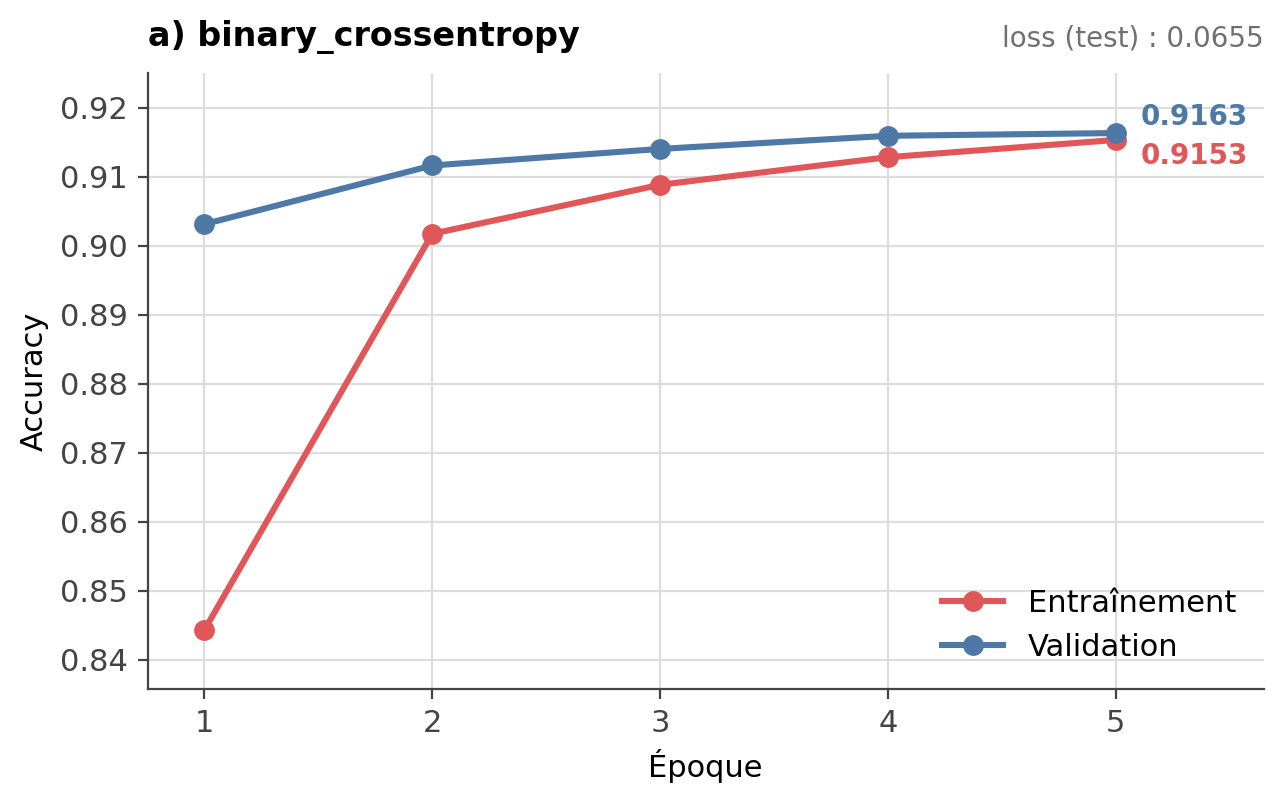

In [15]:
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = classifieur_softmax_simple()        # Dense(10, softmax) : 7 850 synapses

# Compile model
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

res_cout["binary_crossentropy"] = entrainer(model, "a) binary_crossentropy")

### b) `categorical_crossentropy`

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9262 - loss: 0.2667 - val_accuracy: 0.9261 - val_loss: 0.2677
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9261 - loss: 0.2677
Test accuracy: 0.9261

--- Model Summary (Neurons and Synapses) ---
Layer: dense_16 (Dense), Parameters: 7850, Neurons: 10, Weights: 7840, Bias: 10, Calculated Synapses (Weights + Bias): 7850

Total Neurons (approx, mainly from Dense/RNN): 10
Total Synapses (Total Trainable Parameters): 7850


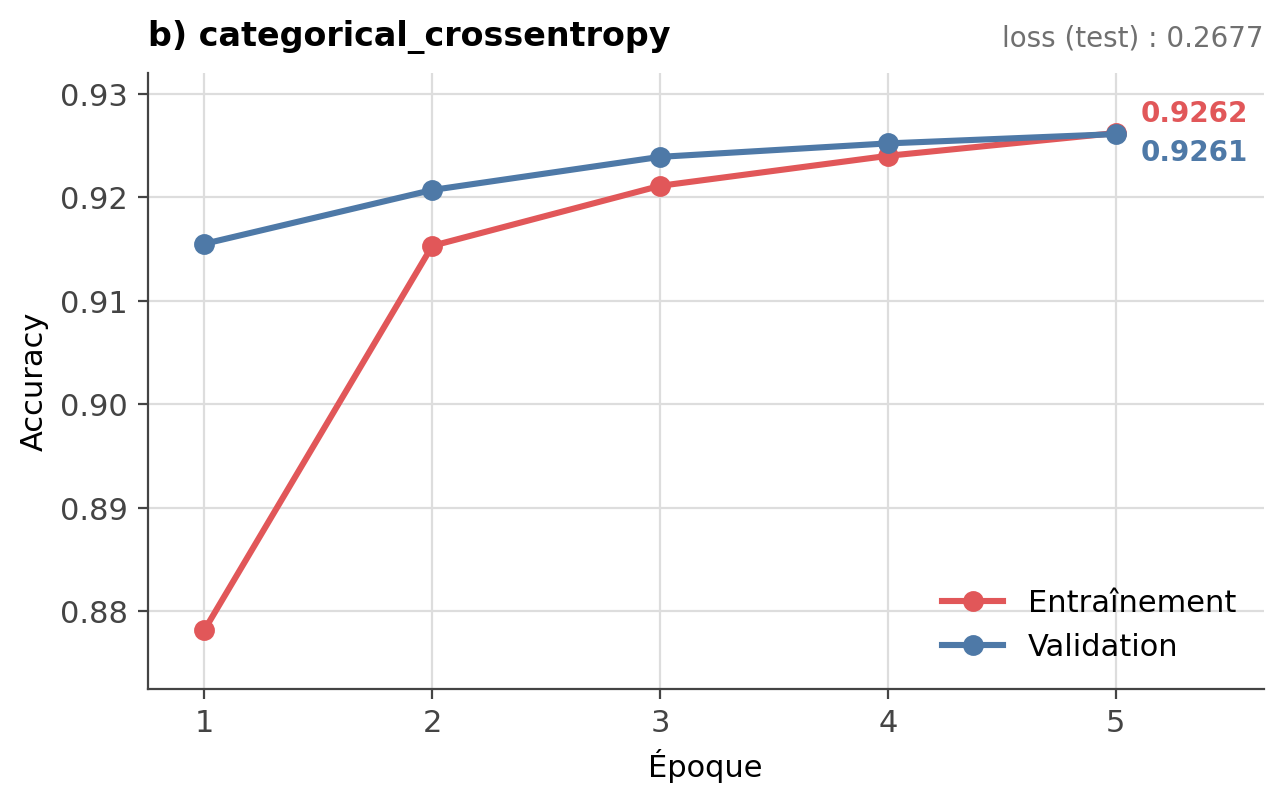

In [16]:
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = classifieur_softmax_simple()        # Dense(10, softmax) : 7 850 synapses

# Compile model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

res_cout["categorical_crossentropy"] = entrainer(model, "b) categorical_crossentropy")

### c) `sparse_categorical_crossentropy`

Shape of y_train before model.fit: (60000,)
Shape of y_test before model.fit: (10000,)
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9262 - loss: 0.2667 - val_accuracy: 0.9261 - val_loss: 0.2677
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9261 - loss: 0.2677
Test accuracy: 0.9261

--- Model Summary (Neurons and Synapses) ---
Layer: dense_19 (Dense), Parameters: 7850, Neurons: 10, Weights: 7840, Bias: 10, Calculated Synapses (Weights + Bias): 7850

Total Neurons (approx, mainly from Dense/RNN): 10
Total Synapses (Total Trainable Parameters): 7850


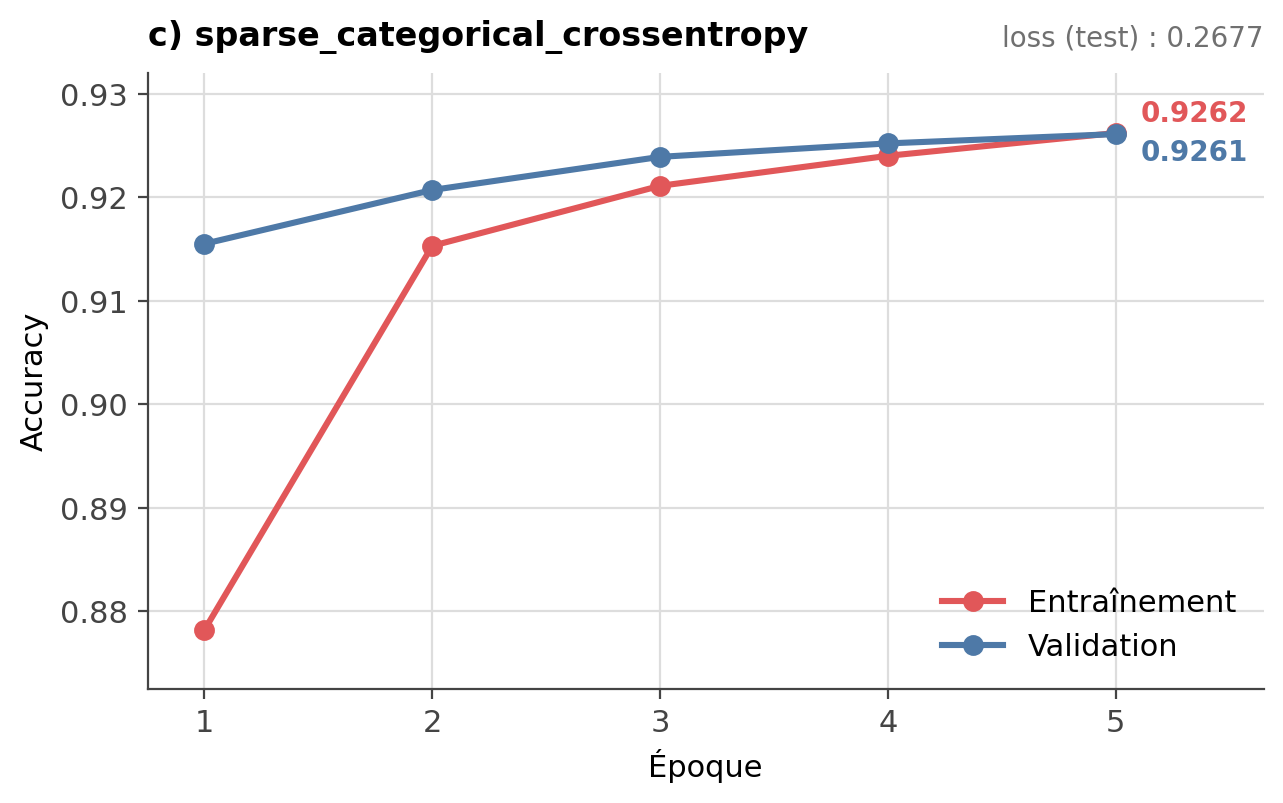

In [17]:
# Keep labels as integer encoding for sparse_categorical_crossentropy
# The original y_train/y_test from load_data() are already integers.
# y_train = tf.keras.utils.to_categorical(y_train, 10) # Removed one-hot encoding
# y_test = tf.keras.utils.to_categorical(y_test, 10)   # Removed one-hot encoding

# Verify the shape of labels before training
print(f"Shape of y_train before model.fit: {y_train.shape}")
print(f"Shape of y_test before model.fit: {y_test.shape}")

# Build a simple softmax classifier
tf.keras.utils.set_random_seed(42)          # même initialisation aléatoire pour chaque expérience
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='softmax', input_shape=(784,))
])

# Compile model with sparse_categorical_crossentropy
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy', # This is now correct for integer labels
              metrics=['accuracy'])

res_cout["sparse_categorical_crossentropy"] = entrainer(
    model, "c) sparse_categorical_crossentropy", y_tr=y_train, y_te=y_test)

### Synthèse

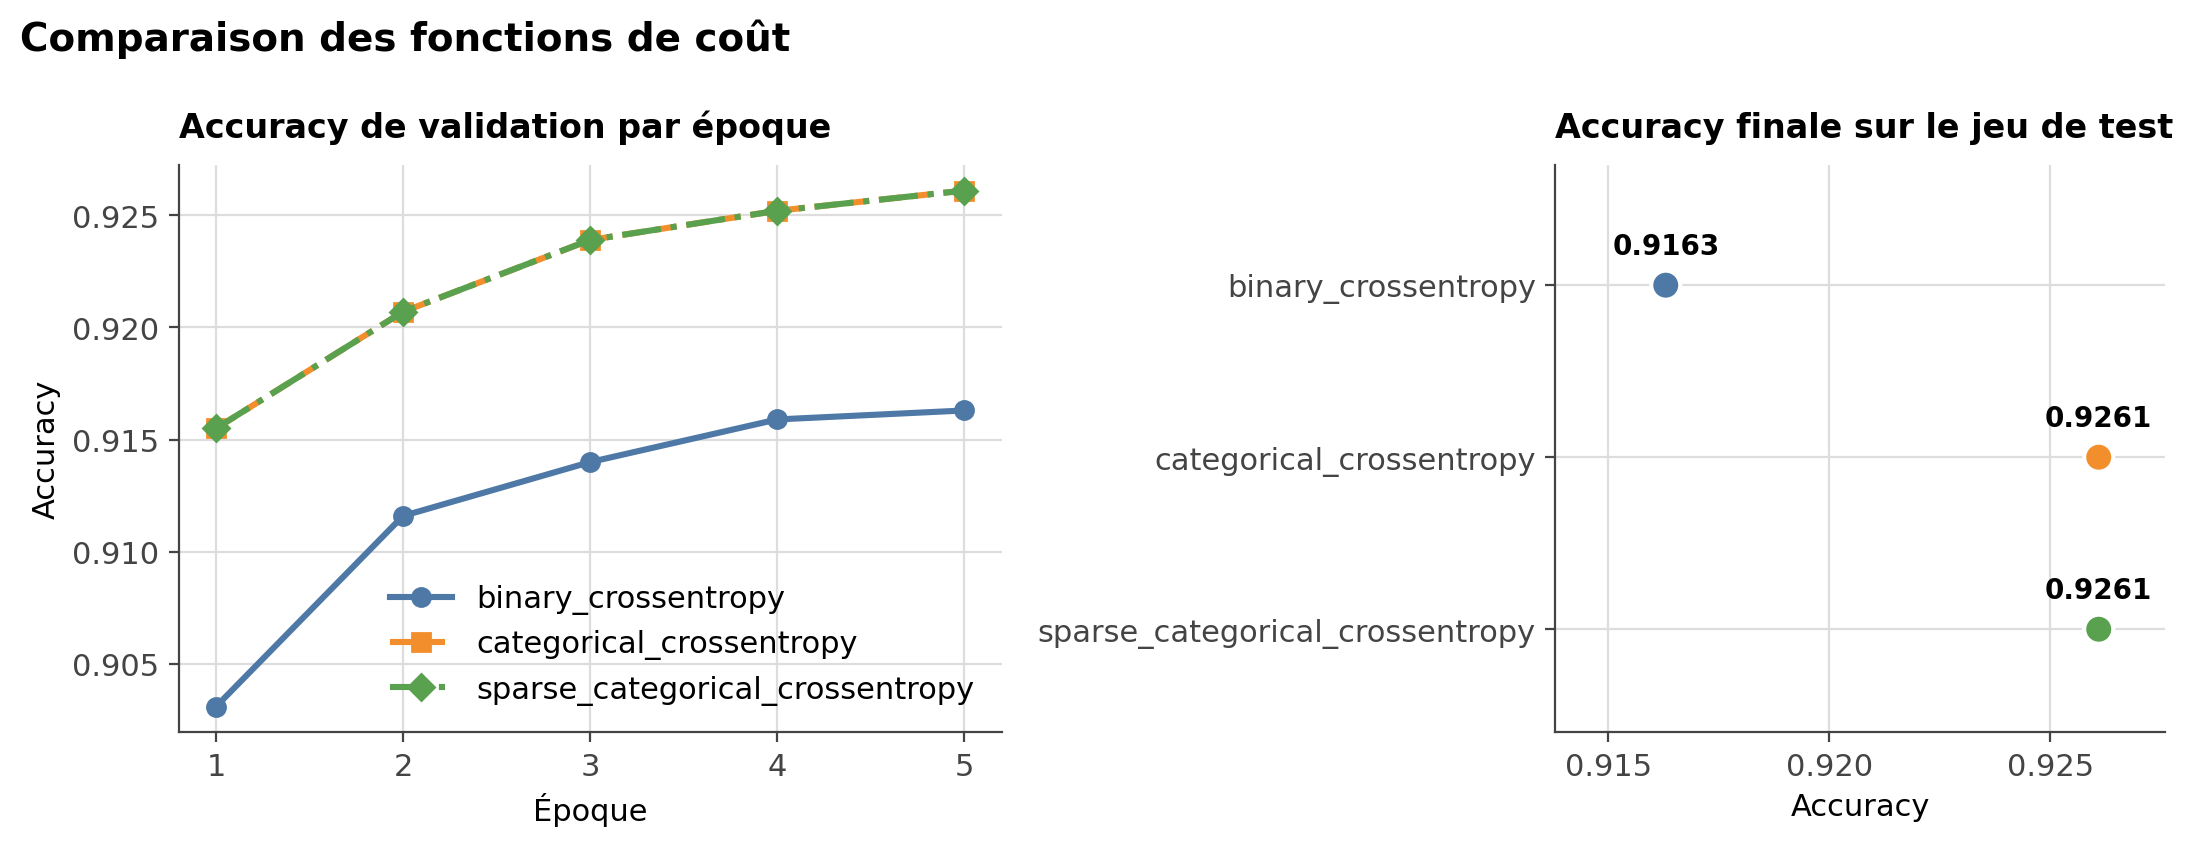

In [18]:
comparer(res_cout, "Comparaison des fonctions de coût")

*Les courbes de `categorical_crossentropy` et de `sparse_categorical_crossentropy` sont superposées : les deux entraînements donnent des résultats identiques.*

### Tableau récapitulatif

| Fonction de coût | Accuracy entraînement | Accuracy test | Époques | Synapses | Conclusion |
|:--|--:|--:|:-:|--:|:--|
| `binary_crossentropy` | 0.9153 | 0.9163 | 5 | 7 850 |  |
| `categorical_crossentropy` | 0.9262 | 0.9261 | 5 | 7 850 |  |
| `sparse_categorical_crossentropy` | 0.9262 | 0.9261 | 5 | 7 850 |  |